#  ENSO-Driven Precipitation Anomaly & Flood-Risk Forecasting Pipeline

**Goal:** forecast regional precipitation anomalies (and a flood-risk indicator) driven by El Niño Southern Oscillation (ENSO), with an end-to-end, leakage-safe, reproducible workflow: **Colab**.

### Pipeline map
| # | Stage | What happens |
|---|-------|--------------|
| 0 | Setup & config | Seeds, region, horizon, paths |
| 1 | Data ingestion | NOAA Niño 3.4 + SOI, NASA POWER regional rain / temp / soil wetness (synthetic fallback if offline) |
| 2 | Causal cleaning | Gap-filling using **only past data** |
| 3 | Feature engineering | ENSO lags 0–6 mo, rolling stats, causal anomalies, interaction / flood-potential features |
| 4 | EDA | Lag-correlation, seasonality, ENSO phase composites |
| 5 | Model training | Ridge baseline vs Random Forest vs Gradient Boosting |
| 6 | Validation | `TimeSeriesSplit` with a gap + final chronological hold-out |
| 7 | Evaluation | R², RMSE, MAE + precision / recall on extreme-rain and flood-risk events |
| 8 | Artifacts | Figures, model, metrics, auto-generated README |
| 9 | GitHub push | Token-authenticated commit & push from Colab |


##  Setup & Configuration
Everything tunable lives in one cell so the experiment is reproducible. The default region is the **Central Kenya highlands** (strong ENSO/Indian-Ocean teleconnection in the Oct–Dec "short rains"); change `LAT`/`LON` to any point on Earth (e.g. Peru coast `-5.2, -80.6`, Southern California `34.0, -118.2`).

In [1]:
import os, json, warnings, subprocess, shutil, platform, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, requests, joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# Configuration
SEED          = 42
LAT, LON      = -0.4, 36.9     # region of interest (degrees)
REGION_NAME   = "Central Kenya Highlands"
START_YEAR, END_YEAR = 1981, 2023
HORIZON       = 1              # forecast lead time in months (predict precip anomaly at t+HORIZON)
MAX_LAG       = 6              # ENSO lags 0..6 months
EXTREME_Q     = 0.80           # top 20% of anomalies = "extreme wet" event
HOLDOUT_FRAC  = 0.20           # final chronological test set
N_SPLITS      = 5
OUT = Path("outputs"); FIG = OUT/"figures"; MODELS = OUT/"models"; DATA = OUT/"data"
for p in (FIG, MODELS, DATA): p.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
print("Python", platform.python_version(), "| pandas", pd.__version__)

Python 3.13.16 | pandas 2.2.3


##  Data Ingestion (Telemetry)
**Sources (all free, no API key):**
- **Niño 3.4 SST anomaly** and **Southern Oscillation Index (SOI)** – NOAA PSL monthly time series.
- **Regional rainfall (`PRECTOTCORR`, mm/day), 2 m temperature (`T2M`), root-zone soil wetness (`GWETROOT`, 0–1)** – NASA POWER monthly point API.

If any download fails (offline / API down), the notebook falls back to a **physically-motivated synthetic generator** so it still runs end-to-end. The variable `DATA_SOURCE` records which path was used.

In [2]:
NINO_URL = "https://psl.noaa.gov/data/correlation/nina34.anom.data"
SOI_URL  = "https://psl.noaa.gov/data/correlation/soi.data"
POWER_URL = ("https://power.larc.nasa.gov/api/temporal/monthly/point?parameters=PRECTOTCORR,T2M,GWETROOT"
             f"&community=AG&longitude={LON}&latitude={LAT}&start={START_YEAR}&end={END_YEAR}&format=JSON")

def parse_psl(url, name):
    """Parse NOAA PSL 'year + 12 monthly values' text files. Missing = -99.99."""
    txt = requests.get(url, timeout=30).text
    rec = {}
    for line in txt.splitlines():
        parts = line.split()
        if len(parts) == 13:
            try:
                yr = int(parts[0]); vals = [float(x) for x in parts[1:]]
            except ValueError:
                continue
            if 1800 < yr < 2100:
                for m, v in enumerate(vals, 1):
                    rec[pd.Timestamp(yr, m, 1)] = np.nan if v <= -99 else v
    return pd.Series(rec, name=name).sort_index()

def fetch_power():
    js = requests.get(POWER_URL, timeout=60).json()["properties"]["parameter"]
    frames = {}
    for var, d in js.items():
        s = {pd.Timestamp(int(k[:4]), int(k[4:]), 1): (np.nan if v <= -990 else v)
             for k, v in d.items() if 1 <= int(k[4:]) <= 12}   # drop the YYYY13 annual rows
        frames[var] = pd.Series(s)
    return pd.DataFrame(frames).sort_index()

def synthetic_data(seed=SEED):
    """Fallback: ENSO-like oscillation teleconnected to rain with a ~3-month delay."""
    rng = np.random.default_rng(seed)
    idx = pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-01", freq="MS")
    n = len(idx); t = np.arange(n)
    nino = (1.1*np.sin(2*np.pi*t/46 + 1.0) + 0.6*np.sin(2*np.pi*t/28)
            + 0.35*rng.normal(size=n)); nino = pd.Series(nino, idx)
    soi  = -0.9*nino + 0.5*rng.normal(size=n)
    m = idx.month.values
    seas = 2.5 + 1.6*np.exp(-0.5*((m-4)/1.3)**2) + 2.0*np.exp(-0.5*((m-11)/1.2)**2)  # bimodal rain
    coupling = 1.4*np.where((m>=10)|(m<=1), 1.0, 0.35)
    rain = seas + coupling*nino.shift(3).bfill().values + 0.8*rng.normal(size=n)
    rain = np.clip(rain, 0, None)
    temp = 17 + 2*np.sin(2*np.pi*(m-2)/12) + 0.02*t/12 + 0.25*nino.shift(2).bfill().values + 0.3*rng.normal(size=n)
    soil = pd.Series(rain).rolling(2, min_periods=1).mean().values/8 + 0.05*rng.normal(size=n)
    soil = np.clip(soil, 0.05, 1.0)
    df = pd.DataFrame({"nino34": nino, "soi": soi, "precip": rain, "temp": temp, "soil": soil}, index=idx)
    return df

try:
    nino = parse_psl(NINO_URL, "nino34"); soi = parse_psl(SOI_URL, "soi"); power = fetch_power()
    raw = pd.concat([nino, soi, power.rename(columns={"PRECTOTCORR":"precip","T2M":"temp","GWETROOT":"soil"})], axis=1)
    raw = raw.loc[f"{START_YEAR}-01-01":f"{END_YEAR}-12-01"]
    assert raw[["precip","temp","soil"]].notna().mean().min() > 0.8 and raw["nino34"].notna().mean() > 0.8
    DATA_SOURCE = "NOAA PSL (Niño 3.4, SOI) + NASA POWER"
except Exception as e:
    print(" Live download failed -> using synthetic fallback:", repr(e)[:150])
    raw = synthetic_data(); DATA_SOURCE = "SYNTHETIC (fallback)"

raw.index.name = "date"
raw.to_csv(DATA/"raw_telemetry.csv")
print("DATA_SOURCE:", DATA_SOURCE, "| shape:", raw.shape)
print("Missing % per column:\n", (raw.isna().mean()*100).round(2).to_string())
raw.head()

DATA_SOURCE: NOAA PSL (Niño 3.4, SOI) + NASA POWER | shape: (516, 5)
Missing % per column:
 nino34    0.0
soi       0.0
soil      0.0
precip    0.0
temp      0.0


,nino34,soi,soil,precip,temp
date,,,,,
1981-01-01,-0.45,0.6,0.40,0.60,16.23
1981-02-01,-0.42,-0.3,0.38,0.99,17.56
1981-03-01,-0.11,-2.1,0.42,6.60,17.25
1981-04-01,-0.57,-0.2,0.53,8.72,16.26
1981-05-01,-0.29,1.3,0.61,8.50,15.72


##  Handling Missing Telemetry **Without Leakage**
Standard `interpolate(method="linear")` uses the *next* valid observation to fill a gap → **future information leaks into the past**. In an operational forecast you never have that. We use a **causal** strategy instead:

1. **Forward-fill** short gaps (≤ 3 months) – "last known value".
2. Anything still missing → mean of the **previous 6 months only** (`shift(1).rolling(6).mean()`).
3. Leading NaNs (no history) are dropped later.

A boolean `*_was_missing` flag is kept so the model/analyst can see imputed rows.

In [3]:
def causal_impute(s, ffill_limit=3, window=6):
    flag = s.isna()
    out = s.ffill(limit=ffill_limit)
    roll = s.shift(1).rolling(window, min_periods=1).mean()   # past-only statistic
    out = out.fillna(roll)
    return out, flag

df = raw.copy()
for c in ["nino34", "soi", "precip", "temp", "soil"]:
    df[c], f = causal_impute(df[c])
    df[f"{c}_was_missing"] = f
print("Remaining NaNs after causal imputation:\n", df[["nino34","soi","precip","temp","soil"]].isna().sum().to_string())

Remaining NaNs after causal imputation:
 nino34    0
soi       0
precip    0
temp      0
soil      0


##  Feature Engineering (Domain-Specific)

**Why lags?** Equatorial Pacific warming/cooling reshapes atmospheric circulation (Walker cell) and the effect on regional rainfall arrives **weeks to months later**. So at forecast time *t* we feed the model Niño 3.4 at *t, t-1, …, t-6*.

**Stationarity / normalisation**
- **Seasonality removal:** rainfall *anomaly* = observed − climatology for that calendar month, where the climatology is an **expanding mean using only previous years** (no look-ahead).
- **Detrending:** temperature/soil anomalies minus a **causal 60-month rolling mean** (removes warming trend without future data).
- **Scaling:** `StandardScaler` is placed **inside** the sklearn `Pipeline`, so it is re-fit on each training fold only.

**Features**
| Group | Features |
|---|---|
| Primary ENSO | `nino34_lag0..6`, `soi_lag0,1,3,6`, rolling means (3/6 mo), 3-month tendency, El Niño / La Niña phase flags |
| Local compounding | soil-wetness anomaly, temperature anomaly (detrended), recent rainfall anomaly lags (persistence) |
| Baseline | climatological mean rainfall for the target month, month sin/cos |
| **Interactions** | `nino_lag3 × soil_anom`, `nino_roll3 × soil_wetness` (**flash-flood potential index**) |

**Target:** precipitation anomaly at **t + HORIZON**.

In [4]:
def causal_month_climatology(s, min_years=5):
    """Mean of the SAME calendar month over strictly PREVIOUS years (shift(1) -> no leakage)."""
    return s.groupby(s.index.month).transform(lambda x: x.shift(1).expanding(min_periods=min_years).mean())

def build_features(df, horizon=HORIZON, max_lag=MAX_LAG):
    d = pd.DataFrame(index=df.index)
    d["month_sin"] = np.sin(2*np.pi*df.index.month/12); d["month_cos"] = np.cos(2*np.pi*df.index.month/12)

    # causal anomalies
    clim_p = causal_month_climatology(df["precip"])
    d["clim_precip"] = clim_p                                   # historical baseline
    precip_anom = df["precip"] - clim_p
    temp_anom = df["temp"] - causal_month_climatology(df["temp"])
    temp_anom = temp_anom - temp_anom.rolling(60, min_periods=24).mean()    # causal detrend
    soil_anom = df["soil"] - causal_month_climatology(df["soil"])
    soil_anom = soil_anom - soil_anom.rolling(60, min_periods=24).mean()

    # ENSO lags
    for l in range(0, max_lag+1):
        d[f"nino34_lag{l}"] = df["nino34"].shift(l)
    for l in (0, 1, 3, 6):
        d[f"soi_lag{l}"] = df["soi"].shift(l)
    d["nino34_roll3"] = df["nino34"].rolling(3).mean()
    d["nino34_roll6"] = df["nino34"].rolling(6).mean()
    d["nino34_tend3"] = df["nino34"] - df["nino34"].shift(3)
    d["is_el_nino"] = (df["nino34"] >= 0.5).astype(int)
    d["is_la_nina"] = (df["nino34"] <= -0.5).astype(int)

    # local compounding variables
    d["soil_anom"] = soil_anom; d["soil_wetness"] = df["soil"]; d["temp_anom"] = temp_anom
    for l in (0, 1, 2):
        d[f"precip_anom_lag{l}"] = precip_anom.shift(l)

    # interactions / composite indices
    d["nino3_x_soil"]        = d["nino34_lag3"] * d["soil_anom"]
    d["flood_potential_idx"] = d["nino34_roll3"] * d["soil_wetness"]

    d["target"] = precip_anom.shift(-horizon)                  # what we forecast
    d["target_date"] = df.index.to_series().shift(-horizon)
    return d, precip_anom

feat, precip_anom = build_features(df)
data = feat.dropna().copy()
FEATURES = [c for c in data.columns if c not in ("target", "target_date")]
print(f"{len(FEATURES)} features | {len(data)} usable monthly samples "
      f"({data.index.min():%Y-%m} -> {data.index.max():%Y-%m})")
data.to_csv(DATA/"model_table.csv")
data.head(3)

27 features | 432 usable monthly samples (1987-12 -> 2023-11)


,month_sin,month_cos,clim_precip,nino34_lag0,nino34_lag1,nino34_lag2,nino34_lag3,nino34_lag4,nino34_lag5,nino34_lag6,...,soil_anom,soil_wetness,temp_anom,precip_anom_lag0,precip_anom_lag1,precip_anom_lag2,nino3_x_soil,flood_potential_idx,target,target_date
date,,,,,,,,,,,,,,,,,,,,,
1987-12-01,-2.449294e-16,1.000000,4.011667,0.89,1.08,1.15,1.18,1.05,0.98,0.84,...,-0.046514,0.47,0.655944,-2.321667,1.585000,-2.471667,-0.054886,0.488800,2.354286,1988-01-01
1988-01-01,5.000000e-01,0.866025,0.865714,0.74,0.89,1.08,1.15,1.18,1.05,0.98,...,-0.006482,0.44,0.271992,2.354286,-2.321667,1.585000,-0.007454,0.397467,-0.202857,1988-02-01
1988-02-01,8.660254e-01,0.500000,1.292857,0.15,0.74,0.89,1.08,1.15,1.18,1.05,...,-0.014474,0.40,0.080212,-0.202857,2.354286,-2.321667,-0.015632,0.237333,-0.742857,1988-03-01


##  Exploratory Data Analysis
Four views: (a) raw telemetry, (b) **lag-correlation** between Niño 3.4 and rainfall anomaly (reveals the teleconnection delay and which lags matter), (c) rainfall seasonality, (d) rainfall anomaly composites by ENSO phase.

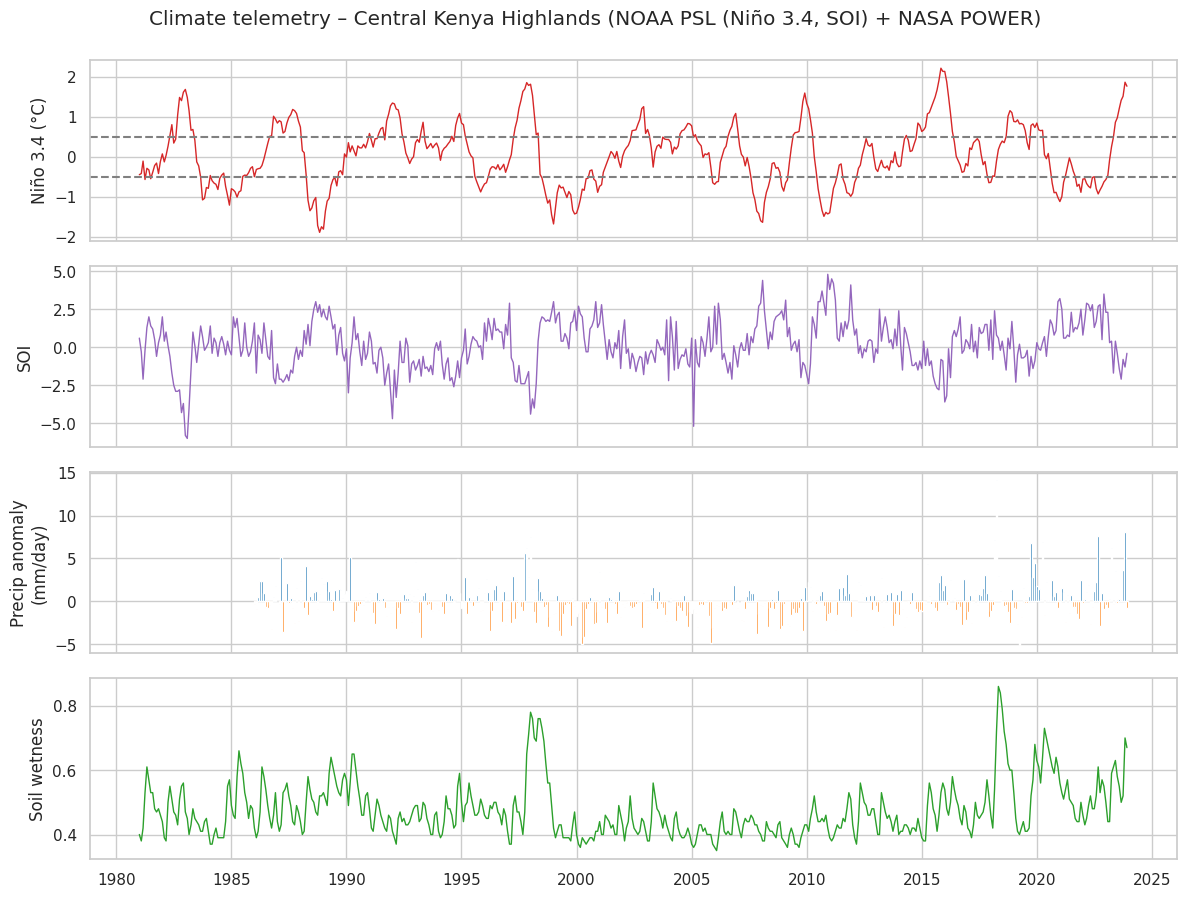

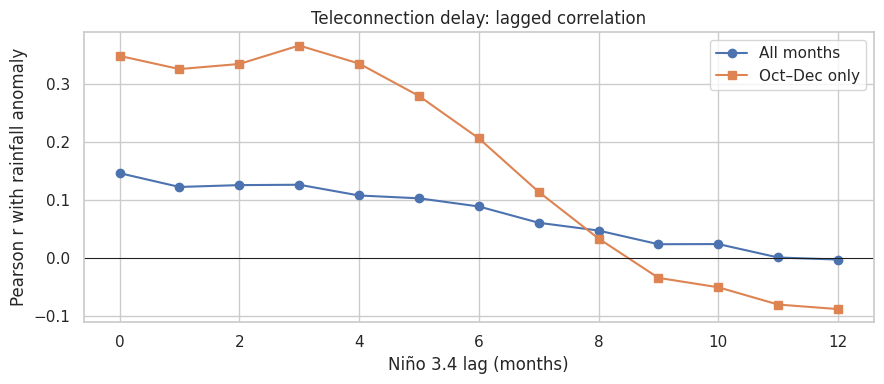

Strongest lag (all months): 0 months


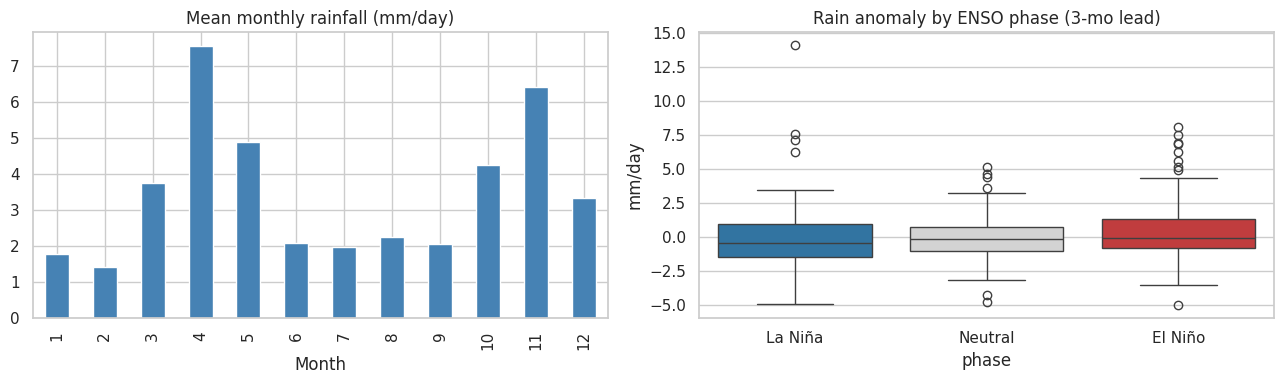

In [5]:
# (a) telemetry overview
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
ax[0].plot(df.index, df["nino34"], color="tab:red", lw=1); ax[0].axhline(0.5, ls="--", c="grey"); ax[0].axhline(-0.5, ls="--", c="grey")
ax[0].set_ylabel("Niño 3.4 (°C)")
ax[1].plot(df.index, df["soi"], color="tab:purple", lw=1); ax[1].set_ylabel("SOI")
ax[2].bar(precip_anom.index, precip_anom, width=25, color=np.where(precip_anom>=0, "tab:blue", "tab:orange")); ax[2].set_ylabel("Precip anomaly\n(mm/day)")
ax[3].plot(df.index, df["soil"], color="tab:green", lw=1); ax[3].set_ylabel("Soil wetness")
fig.suptitle(f"Climate telemetry – {REGION_NAME} ({DATA_SOURCE})", y=0.995)
plt.tight_layout(); fig.savefig(FIG/"01_telemetry_overview.png", dpi=150); plt.show()

# (b) lag-correlation
lags = range(0, 13)
corr = [precip_anom.corr(df["nino34"].shift(l)) for l in lags]
corr_oND = [precip_anom[precip_anom.index.month.isin([10,11,12])].corr(df["nino34"].shift(l)[precip_anom.index.month.isin([10,11,12])]) for l in lags]
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(list(lags), corr, "o-", label="All months"); ax.plot(list(lags), corr_oND, "s-", label="Oct–Dec only")
ax.axhline(0, c="k", lw=.7); ax.set_xlabel("Niño 3.4 lag (months)"); ax.set_ylabel("Pearson r with rainfall anomaly")
ax.set_title("Teleconnection delay: lagged correlation"); ax.legend(); plt.tight_layout()
fig.savefig(FIG/"02_lag_correlation.png", dpi=150); plt.show()
print("Strongest lag (all months):", int(np.argmax(np.abs(corr))), "months")

# (c) seasonality + (d) ENSO phase composite
phase = pd.cut(df["nino34"].shift(3), [-9, -0.5, 0.5, 9], labels=["La Niña", "Neutral", "El Niño"])
comp = pd.DataFrame({"anom": precip_anom, "phase": phase, "month": df.index.month}).dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df.index.month)["precip"].mean().plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Mean monthly rainfall (mm/day)"); ax[0].set_xlabel("Month")
sns.boxplot(data=comp, x="phase", y="anom", ax=ax[1], palette=["tab:blue", "lightgrey", "tab:red"])
ax[1].set_title("Rain anomaly by ENSO phase (3-mo lead)"); ax[1].set_ylabel("mm/day")
plt.tight_layout(); fig.savefig(FIG/"03_seasonality_phase.png", dpi=150); plt.show()

##  Chronological Split & Model Choice

### Splitting (no leakage)
1. **Final hold-out** = the last 20 % of the timeline, touched **once** at the end.
2. Model selection uses **`TimeSeriesSplit` (rolling-origin / expanding window)** on the first 80 %, with `gap=HORIZON` so that a training target never overlaps the validation period.

>  Random `KFold` would put 2015 rows in the training set while validating on 2012 – the model would "see the future" and overstate skill.

### Models & trade-offs
| Model | Why include it |
|---|---|
| **Climatology (predict 0 anomaly)** | Skill floor – any real model must beat this |
| **Ridge** | Linear baseline; shows how much *non-linearity* adds |
| **Random Forest** | Captures thresholds/interactions (e.g. ENSO effect only when soils are saturated), robust to outliers, little tuning |
| **Gradient Boosting (HistGB)** | Usually the strongest tabular learner; sequential error correction handles tipping-point behaviour |

Tree ensembles are preferred over linear regression because ENSO teleconnections are **non-linear, phase-asymmetric (El Niño ≠ −La Niña) and season-dependent**, and need no feature-scaling assumptions. *LSTM/TCN* are natural extensions (see final section) but need far more data than ~500 monthly samples, so we keep them as a benchmark idea rather than the primary model.

In [6]:
n = len(data); split = int(n*(1-HOLDOUT_FRAC))
train_df, test_df = data.iloc[:split], data.iloc[split:]
X_tr, y_tr = train_df[FEATURES], train_df["target"]
X_te, y_te = test_df[FEATURES],  test_df["target"]
print(f"Train: {train_df.index.min():%Y-%m} -> {train_df.index.max():%Y-%m} ({len(train_df)})")
print(f"Test : {test_df.index.min():%Y-%m} -> {test_df.index.max():%Y-%m} ({len(test_df)})")

models = {
    "Ridge": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=10.0))]),
    "RandomForest": Pipeline([("sc", StandardScaler()),
        ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED))]),
    "GradientBoosting": Pipeline([("sc", StandardScaler()),
        ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_depth=3, l2_regularization=0.5, random_state=SEED))]),
}

def event_metrics(y_train, y_true, y_pred, soil_anom, q=EXTREME_Q):
    """Operational metrics. Threshold derived from TRAINING anomalies only."""
    thr = np.quantile(y_train, q)
    ev_true, ev_pred = (y_true >= thr), (y_pred >= thr)
    # flood-risk: extreme rain AND already-saturated soil
    fl_true, fl_pred = ev_true & (soil_anom > 0), ev_pred & (soil_anom > 0)
    f = lambda fn, a, b: fn(a, b, zero_division=0)
    return {"thr": thr,
            "extreme_precision": f(precision_score, ev_true, ev_pred), "extreme_recall": f(recall_score, ev_true, ev_pred),
            "extreme_f1": f(f1_score, ev_true, ev_pred),
            "flood_precision": f(precision_score, fl_true, fl_pred), "flood_recall": f(recall_score, fl_true, fl_pred)}

def all_metrics(y_train, y_true, y_pred, soil_anom):
    m = {"R2": r2_score(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
         "MAE": mean_absolute_error(y_true, y_pred)}
    m.update(event_metrics(y_train, y_true, y_pred, soil_anom)); return m

Train: 1987-12 -> 2016-08 (345)
Test : 2016-09 -> 2023-11 (87)


##  Rolling-Origin Cross-Validation
`TimeSeriesSplit(n_splits=5, gap=HORIZON)` – each fold trains on all history up to a cutoff and validates on the *next* block. Also reports the **climatology baseline** (predict zero anomaly) for honest comparison.

fold 1: train 1987-12->1992-10 | val 1992-12->1997-08
fold 2: train 1987-12->1997-07 | val 1997-09->2002-05
fold 3: train 1987-12->2002-04 | val 2002-06->2007-02
fold 4: train 1987-12->2007-01 | val 2007-03->2011-11
fold 5: train 1987-12->2011-10 | val 2011-12->2016-08


,R2,RMSE,MAE,extreme_precision,extreme_recall,extreme_f1,flood_precision,flood_recall
model,,,,,,,,
Climatology(0),-0.111,1.735,1.295,0.000,0.000,0.000,0.000,0.000
RandomForest,-0.191,1.820,1.383,0.211,0.083,0.112,0.200,0.114
Ridge,-0.194,1.825,1.365,0.000,0.000,0.000,0.000,0.000
GradientBoosting,-0.565,2.045,1.593,0.106,0.156,0.118,0.195,0.222


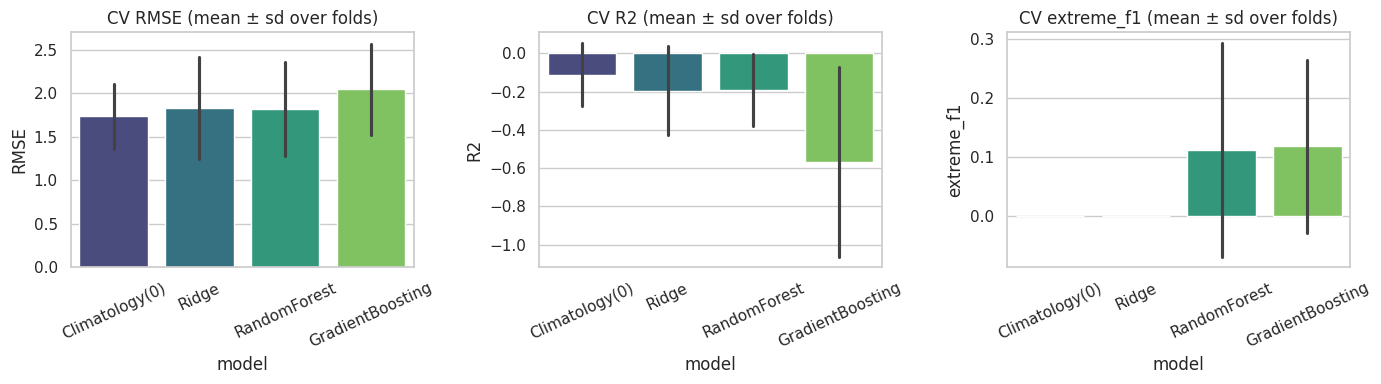

 Best model by CV RMSE: RandomForest


In [7]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS, gap=HORIZON)
rows = []
for fold, (tr, va) in enumerate(tscv.split(X_tr), 1):
    Xa, ya, Xb, yb = X_tr.iloc[tr], y_tr.iloc[tr], X_tr.iloc[va], y_tr.iloc[va]
    soil_b = Xb["soil_anom"].values
    rows.append({"fold": fold, "model": "Climatology(0)", **all_metrics(ya, yb, np.zeros(len(yb)), soil_b)})
    for name, mdl in models.items():
        mdl.fit(Xa, ya)
        rows.append({"fold": fold, "model": name, **all_metrics(ya, yb, mdl.predict(Xb), soil_b)})
    print(f"fold {fold}: train {Xa.index.min():%Y-%m}->{Xa.index.max():%Y-%m} | val {Xb.index.min():%Y-%m}->{Xb.index.max():%Y-%m}")

cv = pd.DataFrame(rows); cv.to_csv(DATA/"cv_results.csv", index=False)
cv_summary = cv.groupby("model")[["R2","RMSE","MAE","extreme_precision","extreme_recall","extreme_f1","flood_precision","flood_recall"]].mean().round(3).sort_values("RMSE")
display(cv_summary)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, met in zip(ax, ["RMSE", "R2", "extreme_f1"]):
    sns.barplot(data=cv, x="model", y=met, ax=a, errorbar="sd", palette="viridis"); a.set_title(f"CV {met} (mean ± sd over folds)"); a.tick_params(axis="x", rotation=25)
plt.tight_layout(); fig.savefig(FIG/"04_cv_comparison.png", dpi=150); plt.show()

best_name = cv_summary.drop(index="Climatology(0)", errors="ignore").index[0]
print(" Best model by CV RMSE:", best_name)

##  Final Hold-out Evaluation & Interpretation
The best model is refit on the full training window and scored **once** on the untouched hold-out. We then:
- plot predictions vs. observations with the **extreme-event threshold**,
- show **permutation importance** (are lagged ENSO and the interaction features actually used?).

Hold-out results (all models):


,R2,RMSE,MAE,thr,extreme_precision,extreme_recall,extreme_f1,flood_precision,flood_recall
Climatology(0),-0.074,2.927,1.907,0.912,0.0,0.000,0.000,0.000,0.00
Ridge,-0.050,2.894,2.001,0.912,0.4,0.182,0.250,0.357,0.25
RandomForest,-0.101,2.964,1.983,0.912,0.5,0.030,0.057,0.500,0.05
GradientBoosting,-0.092,2.952,2.051,0.912,0.8,0.121,0.211,0.750,0.15


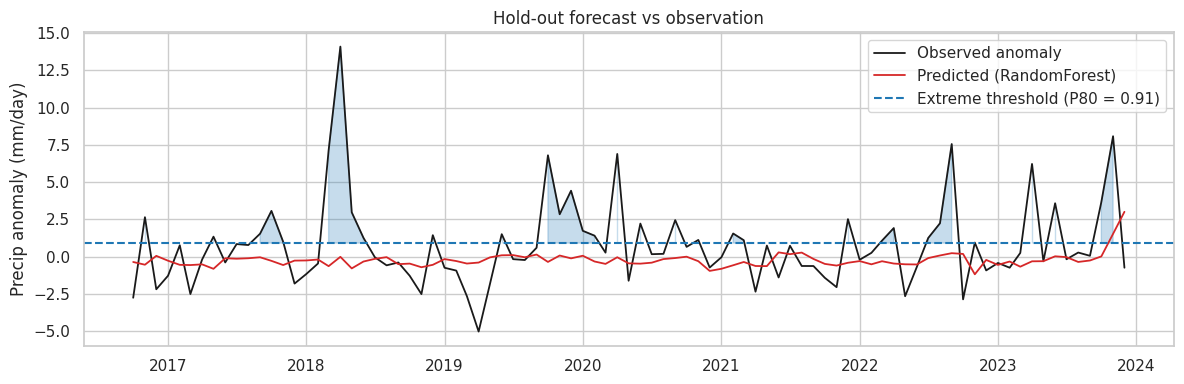

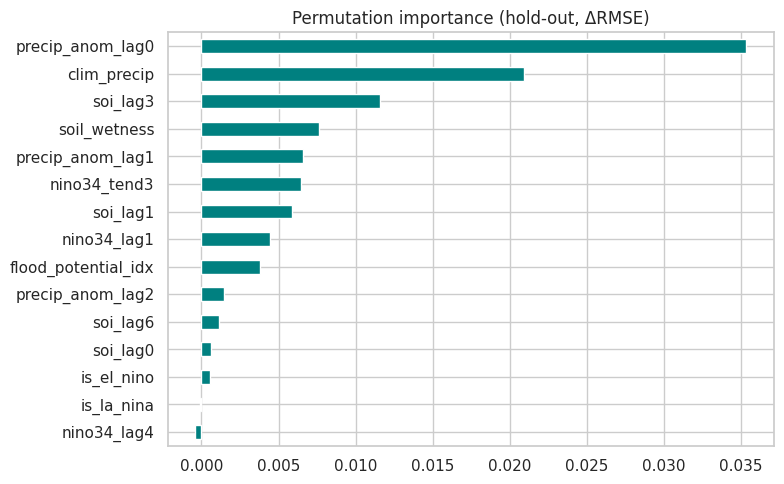

,lead_months,R2,RMSE
0,1,-0.092,2.952
1,2,-0.238,3.143
2,3,-0.217,3.106
3,4,-0.222,3.112
4,6,-0.197,3.080


In [8]:
final = models[best_name].fit(X_tr, y_tr)
pred = final.predict(X_te); soil_te = X_te["soil_anom"].values
holdout = {"Climatology(0)": all_metrics(y_tr, y_te, np.zeros(len(y_te)), soil_te)}
for name, mdl in models.items():
    mdl.fit(X_tr, y_tr); holdout[name] = all_metrics(y_tr, y_te, mdl.predict(X_te), soil_te)
holdout_df = pd.DataFrame(holdout).T.round(3)
print("Hold-out results (all models):"); display(holdout_df)

thr = event_metrics(y_tr, y_te, pred, soil_te)["thr"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_df["target_date"], y_te, label="Observed anomaly", c="k", lw=1.3)
ax.plot(test_df["target_date"], pred, label=f"Predicted ({best_name})", c="tab:red", lw=1.3)
ax.axhline(thr, ls="--", c="tab:blue", label=f"Extreme threshold (P{int(EXTREME_Q*100)} = {thr:.2f})")
ax.fill_between(test_df["target_date"], thr, y_te.where(y_te>=thr), color="tab:blue", alpha=.25)
ax.set_ylabel("Precip anomaly (mm/day)"); ax.set_title("Hold-out forecast vs observation"); ax.legend(); plt.tight_layout()
fig.savefig(FIG/"05_holdout_forecast.png", dpi=150); plt.show()

pi = permutation_importance(final, X_te, y_te, n_repeats=20, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5)); imp[::-1].plot.barh(ax=ax, color="teal")
ax.set_title("Permutation importance (hold-out, ΔRMSE)"); plt.tight_layout(); fig.savefig(FIG/"06_feature_importance.png", dpi=150); plt.show()

# Forecast lead-time sensitivity (does skill decay as we look further ahead?)
lead_rows = []
for h in (1, 2, 3, 4, 6):
    fh, _ = build_features(df, horizon=h); dh = fh.dropna(); s = int(len(dh)*(1-HOLDOUT_FRAC))
    mh = Pipeline([("sc", StandardScaler()), ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_depth=3, l2_regularization=0.5, random_state=SEED))])
    cols = [c for c in dh.columns if c not in ("target", "target_date")]
    mh.fit(dh.iloc[:s][cols], dh.iloc[:s]["target"]); p = mh.predict(dh.iloc[s:][cols])
    lead_rows.append({"lead_months": h, "R2": r2_score(dh.iloc[s:]["target"], p), "RMSE": np.sqrt(mean_squared_error(dh.iloc[s:]["target"], p))})
lead_df = pd.DataFrame(lead_rows).round(3); display(lead_df)

##  Persist Artifacts & Auto-Generate README
Everything the repo needs is written programmatically: trained model (`joblib`), metrics JSON, figures, a `requirements.txt` of pinned versions, a `.gitignore`, and a `README.md` populated with the actual results of this run.

In [9]:
import sklearn
joblib.dump({"model": final, "features": FEATURES, "horizon": HORIZON, "extreme_threshold": float(thr)}, MODELS/"best_model.joblib")

summary = {"data_source": DATA_SOURCE, "region": REGION_NAME, "lat": LAT, "lon": LON, "horizon_months": HORIZON,
           "best_model": best_name, "cv_summary": cv_summary.reset_index().to_dict("records"),
           "holdout": holdout_df.reset_index().rename(columns={"index": "model"}).to_dict("records"),
           "lead_time_sensitivity": lead_df.to_dict("records"), "seed": SEED}
(OUT/"metrics.json").write_text(json.dumps(summary, indent=2, default=float))

(OUT/"requirements.txt").write_text("\n".join([f"numpy=={np.__version__}", f"pandas=={pd.__version__}", f"scikit-learn=={sklearn.__version__}",
    "matplotlib", "seaborn", "requests", "joblib"]) + "\n")
(OUT/".gitignore").write_text("__pycache__/\n*.pyc\n.ipynb_checkpoints/\n")

hb = holdout_df.loc[best_name]
readme = "\n".join([
 "# ENSO-Driven Precipitation Anomaly & Flood-Risk Forecasting", "",
 f"Auto-generated by the Colab pipeline. Region: **{REGION_NAME}** ({LAT}, {LON}). Data: *{DATA_SOURCE}*.", "",
 "## Method", f"- Target: precipitation anomaly **{HORIZON} month(s) ahead** (causal monthly climatology removed).",
 f"- Features: Niño 3.4 lags 0-{MAX_LAG}, SOI lags, rolling stats, soil wetness, temperature anomaly, ENSO×soil interaction features.",
 "- Leakage control: causal imputation, expanding-window climatology, in-pipeline scaling, `TimeSeriesSplit(gap)` + chronological hold-out.", "",
 f"## Results (best model: **{best_name}**, hold-out)",
 f"- R² = {hb['R2']:.3f}, RMSE = {hb['RMSE']:.3f} mm/day, MAE = {hb['MAE']:.3f} mm/day",
 f"- Extreme-rain event (>= P{int(EXTREME_Q*100)}): precision {hb['extreme_precision']:.2f}, recall {hb['extreme_recall']:.2f}, F1 {hb['extreme_f1']:.2f}",
 f"- Flood-risk (extreme rain + saturated soil): precision {hb['flood_precision']:.2f}, recall {hb['flood_recall']:.2f}", "",
 "## Repo layout", "- `figures/` EDA + evaluation plots", "- `models/best_model.joblib` trained pipeline", "- `data/` raw telemetry, model table, CV results",
 "- `metrics.json` machine-readable results", "- `requirements.txt` pinned versions", "",
 "## Reproduce", "Open the notebook in Google Colab and *Run all*. Seed = " + str(SEED) + ".", ""])
(OUT/"README.md").write_text(readme)
print(readme); print("\nFiles:", *sorted(str(p) for p in OUT.rglob("*") if p.is_file()), sep="\n  ")

# ENSO-Driven Precipitation Anomaly & Flood-Risk Forecasting

Auto-generated by the Colab pipeline. Region: **Central Kenya Highlands** (-0.4, 36.9). Data: *NOAA PSL (Niño 3.4, SOI) + NASA POWER*.

## Method
- Target: precipitation anomaly **1 month(s) ahead** (causal monthly climatology removed).
- Features: Niño 3.4 lags 0-6, SOI lags, rolling stats, soil wetness, temperature anomaly, ENSO×soil interaction features.
- Leakage control: causal imputation, expanding-window climatology, in-pipeline scaling, `TimeSeriesSplit(gap)` + chronological hold-out.

## Results (best model: **RandomForest**, hold-out)
- R² = -0.101, RMSE = 2.964 mm/day, MAE = 1.983 mm/day
- Extreme-rain event (>= P80): precision 0.50, recall 0.03, F1 0.06
- Flood-risk (extreme rain + saturated soil): precision 0.50, recall 0.05

## Repo layout
- `figures/` EDA + evaluation plots
- `models/best_model.joblib` trained pipeline
- `data/` raw telemetry, model table, CV results
- `metrics.json` machine-readable results
-

## Discussion, Limitations & Next Steps

**Key takeaways**
- ENSO's influence shows up with a **lag** – see the lag-correlation plot; the permutation-importance chart shows which lags/interactions the model relies on.
- Skill is judged **against climatology**, not just by R². Skill typically **decays with lead time** (see lead-time table).
- Event metrics matter operationally: a model with modest R² can still give useful **recall on extreme-rain months**. Tune `EXTREME_Q` and the decision threshold to trade false alarms vs missed floods.

**Limitations**
- Monthly resolution can't capture flash floods directly; "flood risk" here is a *monthly wet-anomaly + saturated-soil* proxy. For real flood forecasting use daily/sub-daily rainfall and hydrological models.
- ~40 years of monthly data = small sample; confidence intervals are wide. Other drivers (Indian Ocean Dipole, MJO) are not modelled.
- Gridded reanalysis rainfall (NASA POWER) is not station truth.

**Extensions**
1. Add **IOD / DMI** and **MJO** indices as predictors.
2. Benchmark an **LSTM / TCN** on sliding windows (needs daily data or multiple regions to be worthwhile).
3. Quantile / probabilistic forecasts (`HistGradientBoostingRegressor(loss="quantile")`) for risk bands.
4. Multi-region training (pooled grid cells) to increase sample size.
5. GitHub Actions to re-run monthly when new Niño 3.4 values are published.